# 🌉 Lab 3: BERT & CLIP Practice Notebook
## Text understanding (BERT) → Multimodal alignment (CLIP)

Following Lab 1 (DINO ViT) and Lab 2 (Grounding DINO + SAM), this notebook is the third practice,
covering **language and multimodal models**.

### Part A — BERT: a Transformer that understands text
1. Load BERT and understand tokenization
2. Extract sentence embeddings & sentence similarity
3. Masked Language Modeling (MLM) — experience BERT's training objective
4. Embedding analysis of Dog/Cat text descriptions

### Part B — CLIP: a bridge between image and text
5. Load CLIP and understand its architecture
6. Zero-shot Classification — classify Dog/Cat without training
7. Visualize the Image-Text Similarity Matrix
8. Text prompt engineering experiments
9. Analyze the CLIP embedding space (t-SNE)
10. Comprehensive comparison of Lab 1~3 — DINO vs CLIP

### Core Idea
```
Lab 1: Image ──→ [DINO ViT] ──→ Visual Features (self-supervised)
Lab 2: Image + Text ──→ [Grounding DINO + SAM] ──→ Detection + Segmentation
Lab 3: Text ──→ [BERT] ──→ Text Features
        Image + Text ──→ [CLIP] ──→ Aligned Multimodal Features
```

---

## 0. Environment Setup

In [1]:
# ⚠️ Pin the transformers version (the latest version has CLIP compatibility issues)
!pip install transformers==4.44.2 torch torchvision Pillow matplotlib numpy scikit-learn tqdm requests -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 55.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 37.7 MB/s eta 0:00:00


In [2]:
import os
import random
import tarfile
import requests
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
from tqdm.notebook import tqdm

import torch
import torch.nn.functional as F
from transformers import (
    BertTokenizer, BertModel, BertForMaskedLM,
    CLIPProcessor, CLIPModel, CLIPTokenizerFast,
)
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import accuracy_score, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🖥️ Using device: {device}")

🖥️ Using device: cpu


---
## 1. Data Preparation (same as Labs 1 & 2)

We reuse the Oxford-IIIT Pet images. If the `./data` folder exists, the cache is used.

In [3]:
NUM_IMAGES_PER_CLASS = 50
IMG_DIR = './data'
CACHE_DIR = './cache'
os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(f'{IMG_DIR}/dog', exist_ok=True)
os.makedirs(f'{IMG_DIR}/cat', exist_ok=True)

def download_oxford_pets():
    tar_path = os.path.join(CACHE_DIR, 'images.tar.gz')
    extract_dir = os.path.join(CACHE_DIR, 'images')
    if os.path.exists(extract_dir) and len(os.listdir(extract_dir)) > 100:
        print('   Using cached data.')
        return extract_dir
    url = 'https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz'
    print(f'   Downloading: {url} (about 800MB, only on first run)')
    response = requests.get(url, stream=True, timeout=120)
    total = int(response.headers.get('content-length', 0))
    with open(tar_path, 'wb') as f:
        dl = 0
        for chunk in response.iter_content(chunk_size=1024*1024):
            f.write(chunk); dl += len(chunk)
            if total: print(f'\r   {dl/(1024*1024):.0f}MB / {total/(1024*1024):.0f}MB ({dl/total*100:.0f}%)', end='')
    print('\n   Extracting archive...')
    with tarfile.open(tar_path, 'r:gz') as tar: tar.extractall(CACHE_DIR)
    return os.path.join(CACHE_DIR, 'images')

def organize_dog_cat(src_dir, dst_dir, n):
    dogs = [f for f in sorted(os.listdir(src_dir)) if f[0].islower() and f.endswith(('.jpg','.jpeg','.png'))]
    cats = [f for f in sorted(os.listdir(src_dir)) if f[0].isupper() and f.endswith(('.jpg','.jpeg','.png'))]
    random.shuffle(dogs); random.shuffle(cats)
    for i, f in enumerate(dogs[:n]): Image.open(os.path.join(src_dir, f)).convert('RGB').save(f'{dst_dir}/dog/dog_{i:03d}.jpg')
    for i, f in enumerate(cats[:n]): Image.open(os.path.join(src_dir, f)).convert('RGB').save(f'{dst_dir}/cat/cat_{i:03d}.jpg')

ed = len([f for f in os.listdir(f'{IMG_DIR}/dog') if f.endswith('.jpg')])
ec = len([f for f in os.listdir(f'{IMG_DIR}/cat') if f.endswith('.jpg')])
if ed >= NUM_IMAGES_PER_CLASS and ec >= NUM_IMAGES_PER_CLASS:
    print(f'✅ Data ready: Dogs={ed}, Cats={ec}')
else:
    print('📥 Downloading...'); organize_dog_cat(download_oxford_pets(), IMG_DIR, NUM_IMAGES_PER_CLASS)

# Collect image paths
image_paths, image_labels = [], []
for label in ['dog', 'cat']:
    for f in sorted(os.listdir(f'{IMG_DIR}/{label}')):
        if f.endswith('.jpg'):
            image_paths.append(f'{IMG_DIR}/{label}/{f}')
            image_labels.append(label)
print(f"📂 {len(image_paths)} images: Dog {image_labels.count('dog')}, Cat {image_labels.count('cat')}")

📥 다운로드 중...
   다운로드 중: https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz (약 800MB, 첫 실행만)
   755MB / 755MB (100%)
   압축 해제 중...
📂 100장: Dog 50, Cat 50


---
# Part A: BERT
## 2. Load BERT & Understand Tokenization

**BERT** (Bidirectional Encoder Representations from Transformers, Devlin et al., 2019)
- Understands context with bidirectional self-attention
- Pretrained with MLM (Masked Language Modeling) and NSP (Next Sentence Prediction)
- Strong performance on almost every downstream NLP task

In [4]:
BERT_ID = 'bert-base-uncased'

print(f"📦 Loading BERT: {BERT_ID}")
bert_tokenizer = BertTokenizer.from_pretrained(BERT_ID)
bert_model = BertModel.from_pretrained(BERT_ID).to(device)
bert_model.eval()

bert_mlm = BertForMaskedLM.from_pretrained(BERT_ID).to(device)
bert_mlm.eval()

params = sum(p.numel() for p in bert_model.parameters())
print(f"   ✅ Loaded!")
print(f"   - Parameters: {params / 1e6:.1f}M")
print(f"   - Hidden size: {bert_model.config.hidden_size}")
print(f"   - Layers: {bert_model.config.num_hidden_layers}")
print(f"   - Attention heads: {bert_model.config.num_attention_heads}")
print(f"   - Vocab size: {bert_tokenizer.vocab_size}")

📦 BERT 로드: bert-base-uncased


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertForMaskedLM: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


   ✅ 로드 완료!
   - Parameters: 109.5M
   - Hidden size: 768
   - Layers: 12
   - Attention heads: 12
   - Vocab size: 30522


### Visualize the Tokenization Process

In [5]:
# Show the tokenization process step by step
sentences = [
    "A golden retriever playing in the park.",
    "The cat is sleeping on the sofa.",
    "Dogs and cats are popular pets worldwide.",
]

print("📝 BERT tokenization:\n")
for sent in sentences:
    tokens = bert_tokenizer.tokenize(sent)
    token_ids = bert_tokenizer.encode(sent)

    print(f"  Original:  {sent}")
    print(f"  Tokens:    {tokens}")
    print(f"  Token IDs: {token_ids}")
    print(f"  Decoded:   {bert_tokenizer.decode(token_ids)}")
    print(f"  Token #:   {len(tokens)}")
    print()

📝 BERT 토큰화 과정:

  원문:     A golden retriever playing in the park.
  토큰:     ['a', 'golden', 'retrieve', '##r', 'playing', 'in', 'the', 'park', '.']
  토큰 ID:  [101, 1037, 3585, 12850, 2099, 2652, 1999, 1996, 2380, 1012, 102]
  복원:     [CLS] a golden retriever playing in the park. [SEP]
  토큰 수:  9

  원문:     The cat is sleeping on the sofa.
  토큰:     ['the', 'cat', 'is', 'sleeping', 'on', 'the', 'sofa', '.']
  토큰 ID:  [101, 1996, 4937, 2003, 5777, 2006, 1996, 10682, 1012, 102]
  복원:     [CLS] the cat is sleeping on the sofa. [SEP]
  토큰 수:  8

  원문:     Dogs and cats are popular pets worldwide.
  토큰:     ['dogs', 'and', 'cats', 'are', 'popular', 'pets', 'worldwide', '.']
  토큰 ID:  [101, 6077, 1998, 8870, 2024, 2759, 18551, 4969, 1012, 102]
  복원:     [CLS] dogs and cats are popular pets worldwide. [SEP]
  토큰 수:  8



In [6]:
# Description of special tokens
example = "The dog is cute."
encoded = bert_tokenizer(example, return_tensors='pt')

print("🔤 BERT Special Tokens:")
print(f"  [CLS] = {bert_tokenizer.cls_token} (ID: {bert_tokenizer.cls_token_id}) → token representing the whole sentence")
print(f"  [SEP] = {bert_tokenizer.sep_token} (ID: {bert_tokenizer.sep_token_id}) → sentence separator")
print(f"  [MASK] = {bert_tokenizer.mask_token} (ID: {bert_tokenizer.mask_token_id}) → masked token used in MLM")
print(f"  [PAD] = {bert_tokenizer.pad_token} (ID: {bert_tokenizer.pad_token_id}) → padding")
print()

tokens = bert_tokenizer.convert_ids_to_tokens(encoded['input_ids'][0])
print(f"  Input: '{example}'")
print(f"  Tokens: {tokens}")
print(f"         ↑[CLS]                               ↑[SEP]")

🔤 BERT Special Tokens:
  [CLS] = [CLS] (ID: 101) → 문장 전체를 대표하는 토큰
  [SEP] = [SEP] (ID: 102) → 문장 구분자
  [MASK] = [MASK] (ID: 103) → MLM에서 가려진 토큰
  [PAD] = [PAD] (ID: 0) → 패딩

  입력: 'The dog is cute.'
  토큰: ['[CLS]', 'the', 'dog', 'is', 'cute', '.', '[SEP]']
         ↑[CLS]                               ↑[SEP]


---
## 3. BERT Sentence Embeddings & Sentence Similarity

We use BERT's `[CLS]` token output or **mean pooling** as the sentence embedding.

In [7]:
@torch.no_grad()
def get_bert_embeddings(texts, pooling='mean'):
    """
    Extract sentence embeddings with BERT.

    Args:
        pooling: 'cls' = [CLS] token, 'mean' = average over all tokens
    """
    encoded = bert_tokenizer(
        texts, padding=True, truncation=True,
        max_length=128, return_tensors='pt'
    ).to(device)

    outputs = bert_model(**encoded)

    if pooling == 'cls':
        # Output of the [CLS] token
        embeddings = outputs.last_hidden_state[:, 0, :]
    else:
        # Mean pooling (respecting the attention mask)
        attention_mask = encoded['attention_mask'].unsqueeze(-1)
        token_embeds = outputs.last_hidden_state
        embeddings = (token_embeds * attention_mask).sum(1) / attention_mask.sum(1)

    # L2 normalize
    embeddings = F.normalize(embeddings, p=2, dim=1)
    return embeddings.cpu().numpy()

print("✅ get_bert_embeddings function defined")

✅ get_bert_embeddings 함수 정의 완료


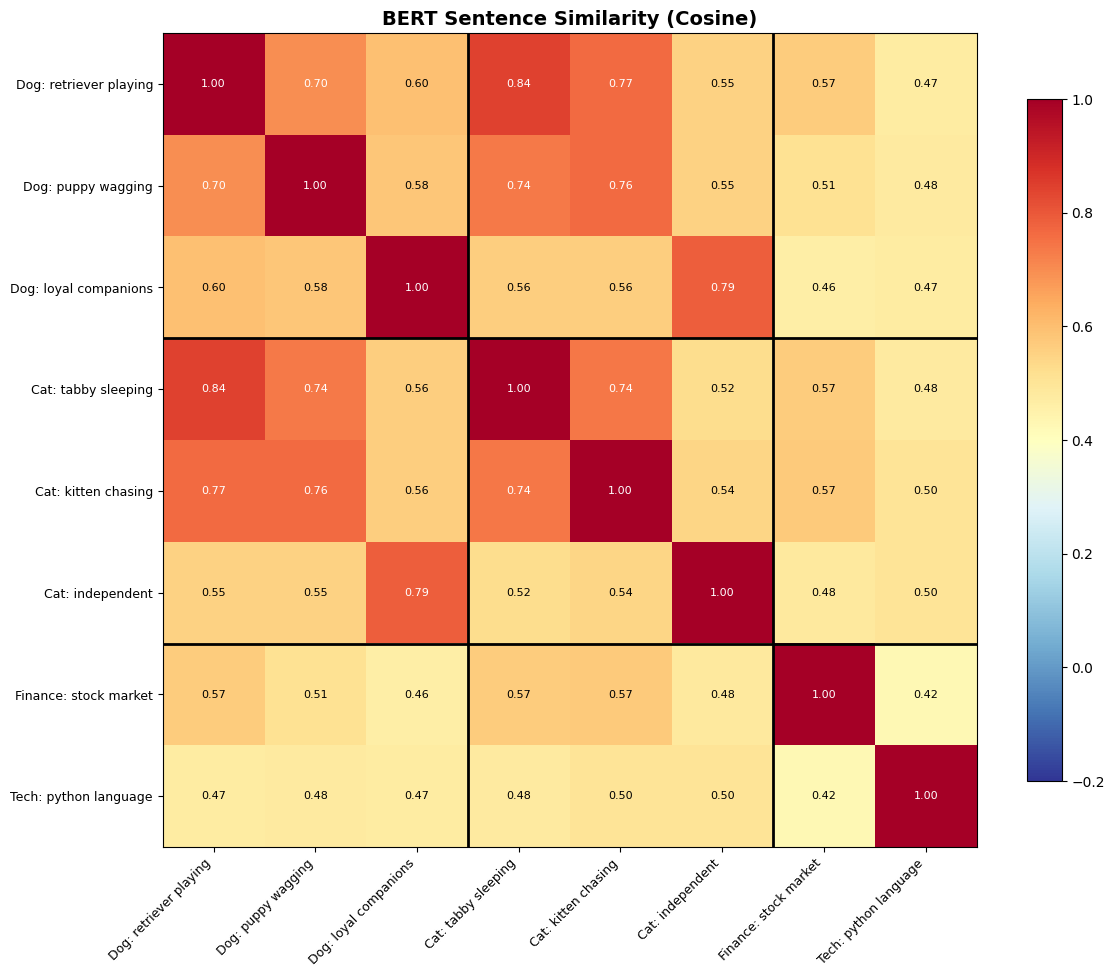

💡 관찰: Dog 관련 문장끼리, Cat 관련 문장끼리 유사도가 높습니다.
   반면 금융/기술 문장과는 유사도가 낮습니다.


In [8]:
# Sentence similarity experiment
test_sentences = [
    # Dog-related
    "A golden retriever playing fetch in the park.",
    "The puppy is wagging its tail happily.",
    "Dogs are loyal and friendly companions.",
    # Cat-related
    "A tabby cat sleeping on the windowsill.",
    "The kitten is chasing a ball of yarn.",
    "Cats are independent and graceful animals.",
    # Unrelated sentences
    "The stock market crashed yesterday.",
    "Python is a popular programming language.",
]

embeddings = get_bert_embeddings(test_sentences)
sim_matrix = cosine_similarity(embeddings)

# Visualization
fig, ax = plt.subplots(figsize=(12, 10))

short_labels = [
    "Dog: retriever playing", "Dog: puppy wagging", "Dog: loyal companions",
    "Cat: tabby sleeping", "Cat: kitten chasing", "Cat: independent",
    "Finance: stock market", "Tech: python language"
]

im = ax.imshow(sim_matrix, cmap='RdYlBu_r', vmin=-0.2, vmax=1)
ax.set_xticks(range(len(short_labels)))
ax.set_yticks(range(len(short_labels)))
ax.set_xticklabels(short_labels, rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(short_labels, fontsize=9)
ax.set_title('BERT Sentence Similarity (Cosine)', fontsize=14, fontweight='bold')

for i in range(len(sim_matrix)):
    for j in range(len(sim_matrix)):
        ax.text(j, i, f'{sim_matrix[i,j]:.2f}', ha='center', va='center', fontsize=8,
               color='white' if abs(sim_matrix[i,j]) > 0.6 else 'black')

# Group divider lines
for pos in [2.5, 5.5]:
    ax.axhline(y=pos, color='black', linewidth=2)
    ax.axvline(x=pos, color='black', linewidth=2)

plt.colorbar(im, shrink=0.8)
plt.tight_layout()
plt.show()

print("💡 Observation: Dog sentences are similar to each other; cat sentences are similar to each other.")
print("   Similarity to the finance/tech sentences is low.")

---
## 4. Masked Language Modeling (MLM)

BERT's core training objective: hide part of a sentence with `[MASK]` and learn to predict the original word.

```
Input:  "The [MASK] is playing in the park."
Predict: dog (95%), cat (2%), child (1%), ...
```

Through this, BERT learns to understand **context** bidirectionally.

In [9]:
@torch.no_grad()
def predict_masked(text, top_k=10):
    """
    Predict the word that fits the position of the [MASK] token.
    """
    inputs = bert_tokenizer(text, return_tensors='pt').to(device)
    outputs = bert_mlm(**inputs)
    logits = outputs.logits  # (1, seq_len, vocab_size)

    # Find the [MASK] positions
    mask_idx = (inputs['input_ids'][0] == bert_tokenizer.mask_token_id).nonzero(as_tuple=True)[0]

    results = []
    for idx in mask_idx:
        mask_logits = logits[0, idx]
        probs = torch.softmax(mask_logits, dim=0)
        top_probs, top_indices = probs.topk(top_k)

        predictions = []
        for prob, token_id in zip(top_probs, top_indices):
            word = bert_tokenizer.decode(token_id.item())
            predictions.append((word, prob.item()))
        results.append(predictions)

    return results

# MLM demo
mlm_examples = [
    "The [MASK] is wagging its tail happily.",
    "A [MASK] is sleeping on the windowsill.",
    "The golden [MASK] is the most popular dog breed.",
    "My pet [MASK] loves to chase mice.",
    "[MASK] are known for their loyalty to humans.",
    "The [MASK] purrs when you stroke its fur.",
]

print("🎭 Masked Language Modeling (BERT)\n")
print("BERT predicts the word that fills [MASK]:\n")

for text in mlm_examples:
    preds = predict_masked(text, top_k=5)
    print(f"  📝 \"{text}\"")
    for mask_preds in preds:
        pred_str = ", ".join([f"{w} ({p:.1%})" for w, p in mask_preds])
        print(f"     → {pred_str}")
    print()

🎭 Masked Language Modeling (BERT)

BERT가 [MASK]에 들어갈 단어를 예측합니다:

  📝 "The [MASK] is wagging its tail happily."
     → d o g (45.6%), c a t (24.7%), b e a r (1.8%), l i o n (1.8%), w o l f (1.3%)

  📝 "A [MASK] is sleeping on the windowsill."
     → w o m a n (20.1%), m a n (18.2%), g i r l (10.7%), b o y (9.3%), c h i l d (7.7%)

  📝 "The golden [MASK] is the most popular dog breed."
     → l i o n (19.6%), f o x (11.0%), d o g (8.4%), b e a r (4.7%), w o l f (4.4%)

  📝 "My pet [MASK] loves to chase mice."
     → c a t (26.2%), d o g (12.3%), m o u s e (6.1%), s q u i r r e l (2.5%), r a b b i t (2.0%)

  📝 "[MASK] are known for their loyalty to humans."
     → t h e y (95.9%), h u m a n s (0.3%), t h e s e (0.2%), d r a g o n s (0.1%), w o l v e s (0.1%)

  📝 "The [MASK] purrs when you stroke its fur."
     → a n i m a l (21.4%), d o g (17.1%), c a t (11.7%), w o l f (6.5%), b e a s t (4.6%)



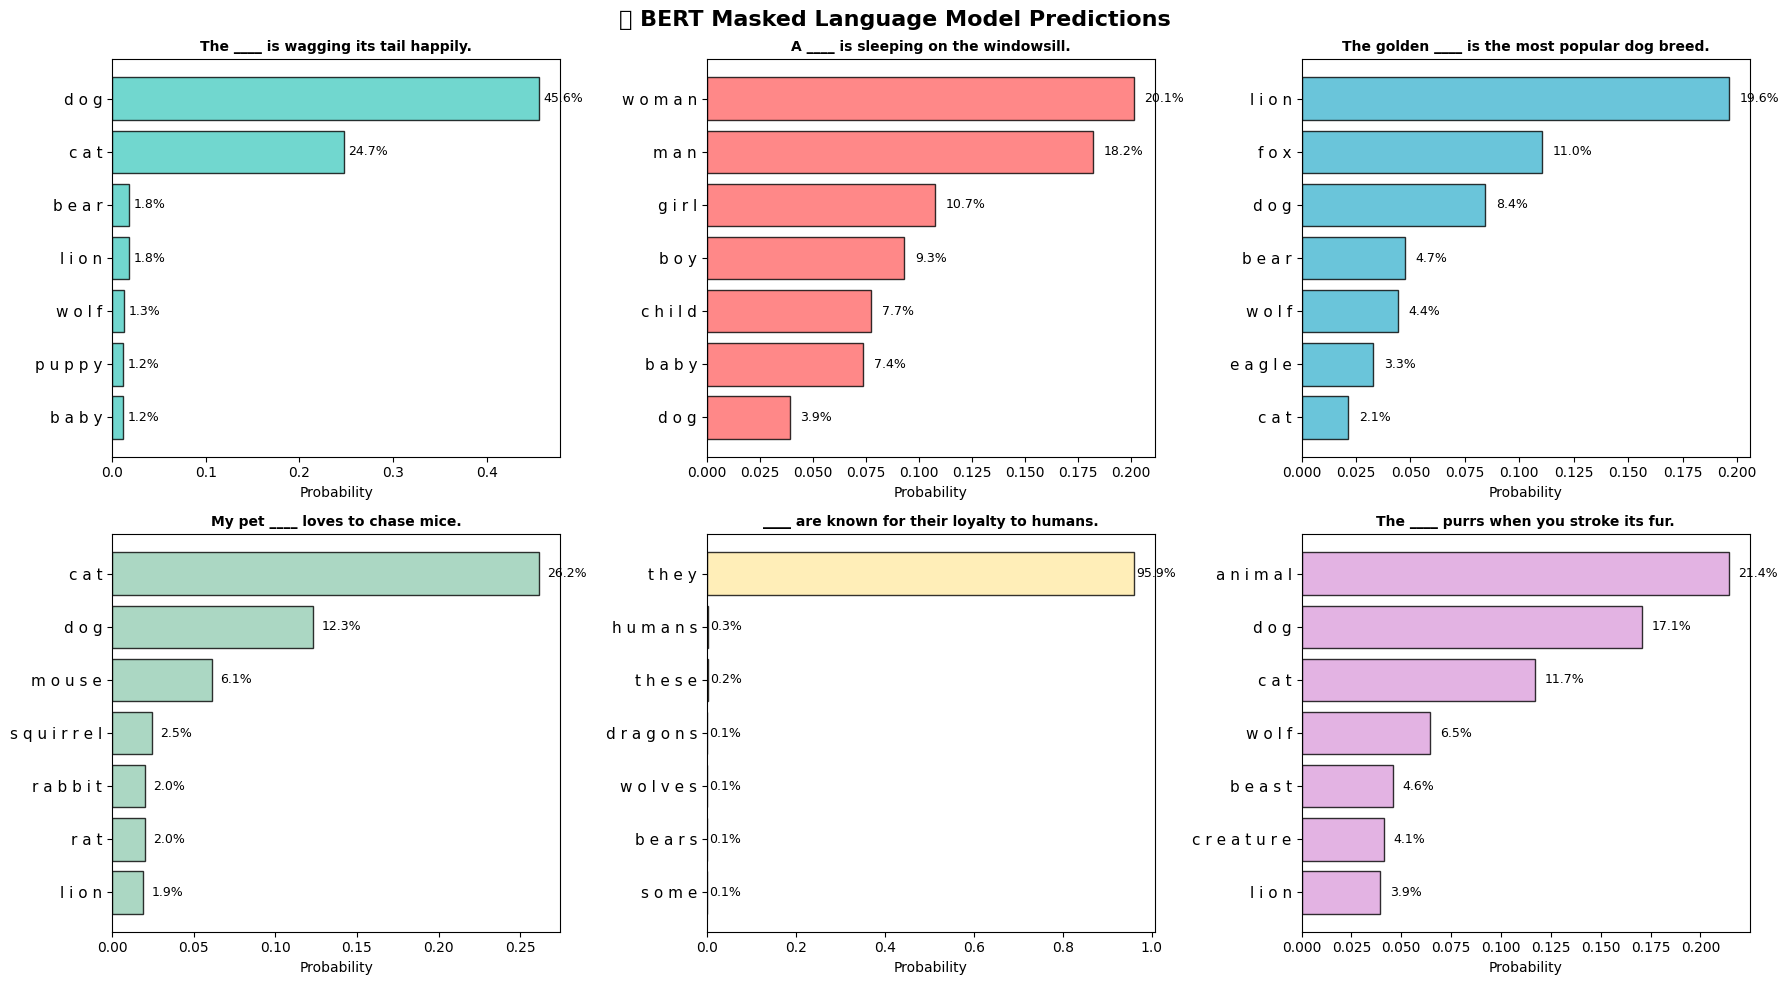

In [10]:
# Visualize MLM predictions as bar charts
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('🎭 BERT Masked Language Model Predictions', fontsize=16, fontweight='bold')

colors = ['#4ECDC4', '#FF6B6B', '#45B7D1', '#96CEB4', '#FFEAA7', '#DDA0DD']

for i, text in enumerate(mlm_examples):
    ax = axes[i // 3, i % 3]
    preds = predict_masked(text, top_k=7)[0]

    words = [p[0] for p in preds]
    probs = [p[1] for p in preds]

    bars = ax.barh(range(len(words)), probs, color=colors[i], alpha=0.8, edgecolor='black')
    ax.set_yticks(range(len(words)))
    ax.set_yticklabels(words, fontsize=11)
    ax.set_xlabel('Probability')
    ax.set_title(text.replace('[MASK]', '____'), fontsize=10, fontweight='bold')
    ax.invert_yaxis()

    for bar, prob in zip(bars, probs):
        ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
               f'{prob:.1%}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

---
## 5. Embedding Analysis of Dog/Cat Text Descriptions

We analyze BERT embeddings of various dog/cat-related texts.

✅ BERT 텍스트 임베딩: (20, 768)


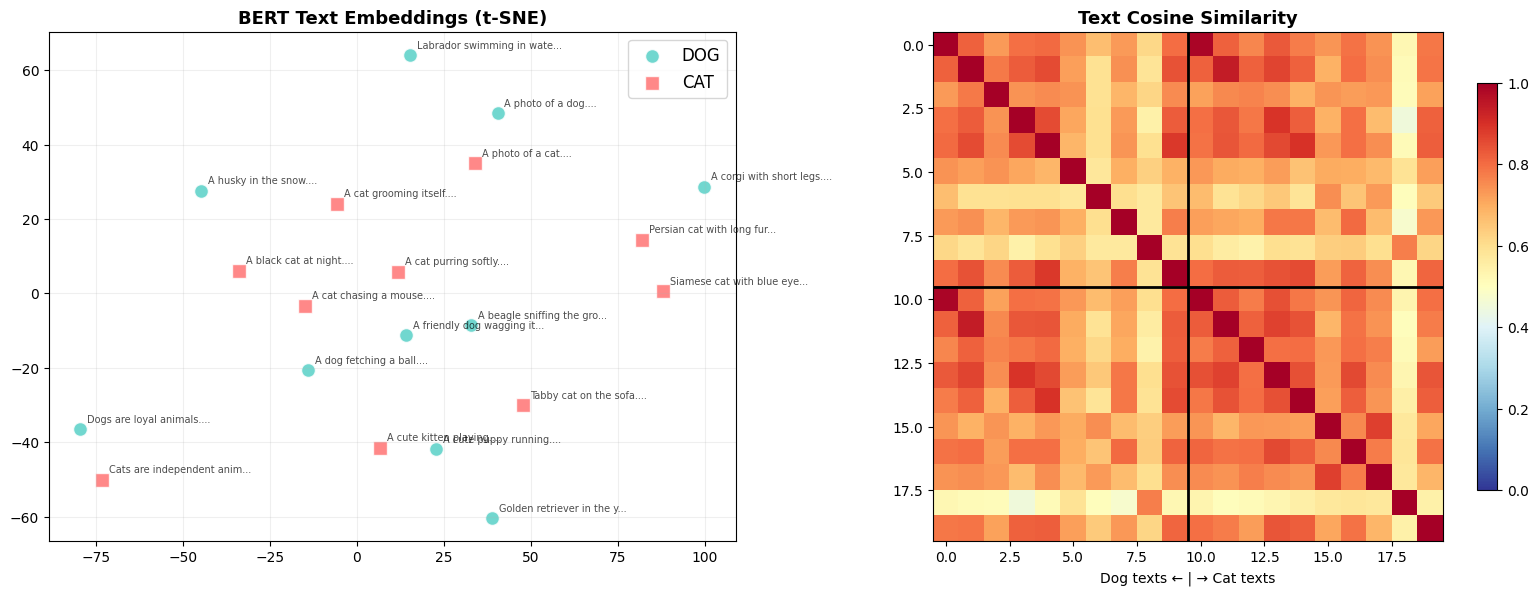

In [11]:
# Dog/Cat-related text descriptions
dog_texts = [
    "A photo of a dog.", "A cute puppy running.",
    "Golden retriever in the yard.", "A dog fetching a ball.",
    "A friendly dog wagging its tail.", "Labrador swimming in water.",
    "A corgi with short legs.", "A husky in the snow.",
    "Dogs are loyal animals.", "A beagle sniffing the ground.",
]

cat_texts = [
    "A photo of a cat.", "A cute kitten playing.",
    "Tabby cat on the sofa.", "A cat chasing a mouse.",
    "A cat purring softly.", "Persian cat with long fur.",
    "A black cat at night.", "Siamese cat with blue eyes.",
    "Cats are independent animals.", "A cat grooming itself.",
]

all_texts = dog_texts + cat_texts
text_labels = ['dog'] * len(dog_texts) + ['cat'] * len(cat_texts)

# Extract BERT embeddings
bert_text_embeds = get_bert_embeddings(all_texts, pooling='mean')
print(f"✅ BERT text embeddings: {bert_text_embeds.shape}")

# t-SNE
tsne = TSNE(n_components=2, perplexity=8, random_state=SEED)
bert_2d = tsne.fit_transform(bert_text_embeds)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# (1) t-SNE
for cls, color, marker in [('dog', '#4ECDC4', 'o'), ('cat', '#FF6B6B', 's')]:
    mask = np.array(text_labels) == cls
    axes[0].scatter(bert_2d[mask, 0], bert_2d[mask, 1], c=color, marker=marker,
                   s=100, alpha=0.8, edgecolors='white', label=cls.upper())
    for i, (x, y) in enumerate(bert_2d[mask]):
        idx = np.where(mask)[0][i]
        axes[0].annotate(all_texts[idx][:25] + '...', (x, y), fontsize=7,
                        textcoords='offset points', xytext=(5, 5), alpha=0.7)

axes[0].set_title('BERT Text Embeddings (t-SNE)', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=12)
axes[0].grid(alpha=0.2)

# (2) Cosine Similarity
sim = cosine_similarity(bert_text_embeds)
im = axes[1].imshow(sim, cmap='RdYlBu_r', vmin=0, vmax=1)
axes[1].axhline(y=len(dog_texts)-0.5, color='black', linewidth=2)
axes[1].axvline(x=len(dog_texts)-0.5, color='black', linewidth=2)
axes[1].set_title('Text Cosine Similarity', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Dog texts ← | → Cat texts')
plt.colorbar(im, ax=axes[1], shrink=0.8)

plt.tight_layout()
plt.show()

---
# Part B: CLIP
## 6. Load CLIP & Understand Its Architecture

**CLIP** (Contrastive Language-Image Pre-training, Radford et al., 2021)
- Contrastive learning over 400M (image, text) pairs
- Aligns Image Encoder (ViT) + Text Encoder (Transformer) into a shared embedding space
- Used for zero-shot classification, image search, multimodal retrieval, etc.

```
Image ──→ [ViT Encoder] ──→ Image Embedding ─┐
                                                ├── Cosine Similarity
Text  ──→ [Text Encoder] ──→ Text Embedding  ─┘
```

In [12]:
CLIP_ID = "openai/clip-vit-base-patch32"

print(f"📦 Loading CLIP: {CLIP_ID}")
clip_processor = CLIPProcessor.from_pretrained(CLIP_ID)
clip_model = CLIPModel.from_pretrained(CLIP_ID).to(device)
clip_model.eval()

clip_params = sum(p.numel() for p in clip_model.parameters())
print(f"   ✅ Loaded!")
print(f"   - Total parameters: {clip_params / 1e6:.1f}M")
print(f"   - Vision (ViT): {sum(p.numel() for p in clip_model.vision_model.parameters())/1e6:.1f}M")
print(f"   - Text:          {sum(p.numel() for p in clip_model.text_model.parameters())/1e6:.1f}M")
print(f"   - Image size:    {clip_model.config.vision_config.image_size}")
print(f"   - Patch size:    {clip_model.config.vision_config.patch_size}")
print(f"   - Embed dim:     {clip_model.config.projection_dim}")

📦 CLIP 로드: openai/clip-vit-base-patch32


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

   ✅ 로드 완료!
   - Total parameters: 151.3M
   - Vision (ViT): 87.5M
   - Text:          63.2M
   - Image size:    224
   - Patch size:    32
   - Embed dim:     512


---
## 7. CLIP Zero-Shot Classification

CLIP's most impressive ability: classifying images **without training**.

Principle: compare the cosine similarity between the image embedding and each class-text embedding,
and pick the class of the most similar text.

In [13]:
@torch.no_grad()
def clip_zero_shot_classify(images, class_texts):
    """
    Perform zero-shot classification with CLIP.

    Args:
        images: list of PIL Image
        class_texts: list of str (e.g., ["a photo of a dog", "a photo of a cat"])

    Returns:
        probs: (N, C) probability matrix
        pred_indices: (N,) predicted class indices
    """
    inputs = clip_processor(
        text=class_texts, images=images,
        return_tensors="pt", padding=True
    ).to(device)

    outputs = clip_model(**inputs)
    logits = outputs.logits_per_image  # (N, C)
    probs = logits.softmax(dim=1).cpu().numpy()
    pred_indices = probs.argmax(axis=1)

    return probs, pred_indices

print("✅ clip_zero_shot_classify function defined")

✅ clip_zero_shot_classify 함수 정의 완료


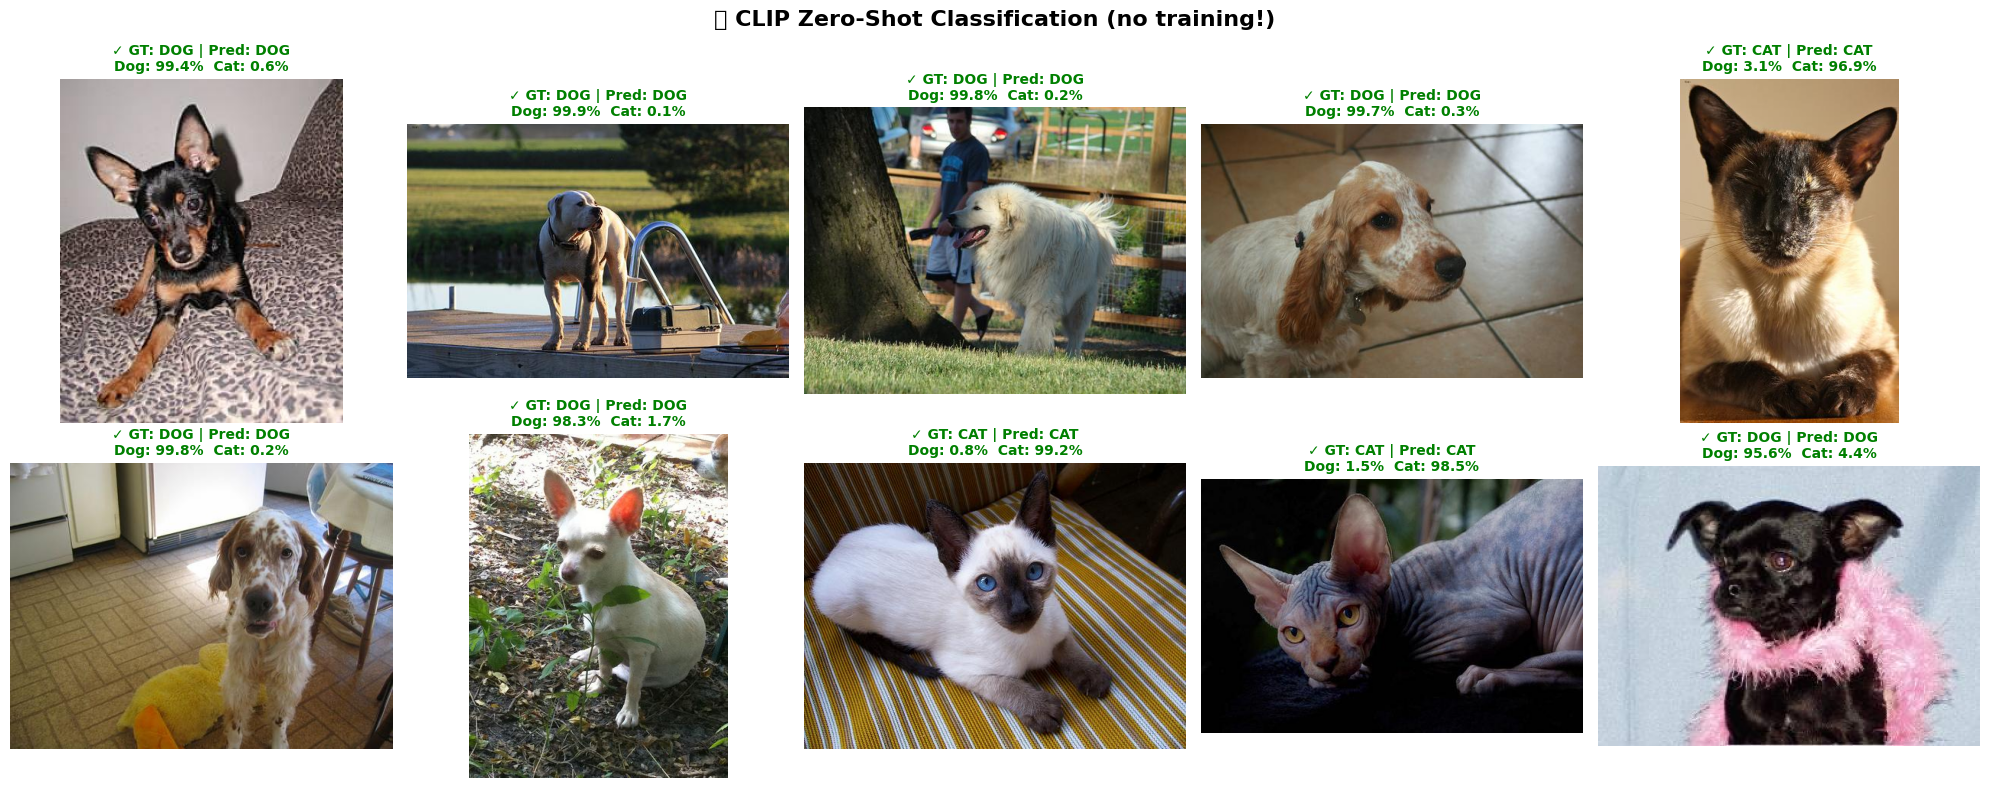

In [14]:
# Demo zero-shot classification on sample images
class_texts = ["a photo of a dog", "a photo of a cat"]
n_show = 10
show_indices = random.sample(range(len(image_paths)), n_show)

fig, axes = plt.subplots(2, n_show // 2, figsize=(4 * (n_show // 2), 8))
fig.suptitle('🎯 CLIP Zero-Shot Classification (no training!)', fontsize=16, fontweight='bold')

for i, idx in enumerate(show_indices):
    ax = axes[i // (n_show // 2), i % (n_show // 2)]
    img = Image.open(image_paths[idx]).convert('RGB')
    gt = image_labels[idx]

    probs, pred_idx = clip_zero_shot_classify([img], class_texts)
    pred = 'dog' if pred_idx[0] == 0 else 'cat'
    correct = pred == gt

    ax.imshow(img)
    symbol = '✓' if correct else '✗'
    color = 'green' if correct else 'red'
    ax.set_title(f'{symbol} GT: {gt.upper()} | Pred: {pred.upper()}\n'
                f'Dog: {probs[0][0]:.1%}  Cat: {probs[0][1]:.1%}',
                fontsize=10, fontweight='bold', color=color)
    ax.axis('off')

plt.tight_layout()
plt.show()

📊 전체 데이터셋에 대해 CLIP Zero-shot Classification 실행 중...



  0%|          | 0/7 [00:00<?, ?it/s]


  🎯 CLIP Zero-Shot Accuracy: 99.0%
  (학습 데이터 0개로 달성!)


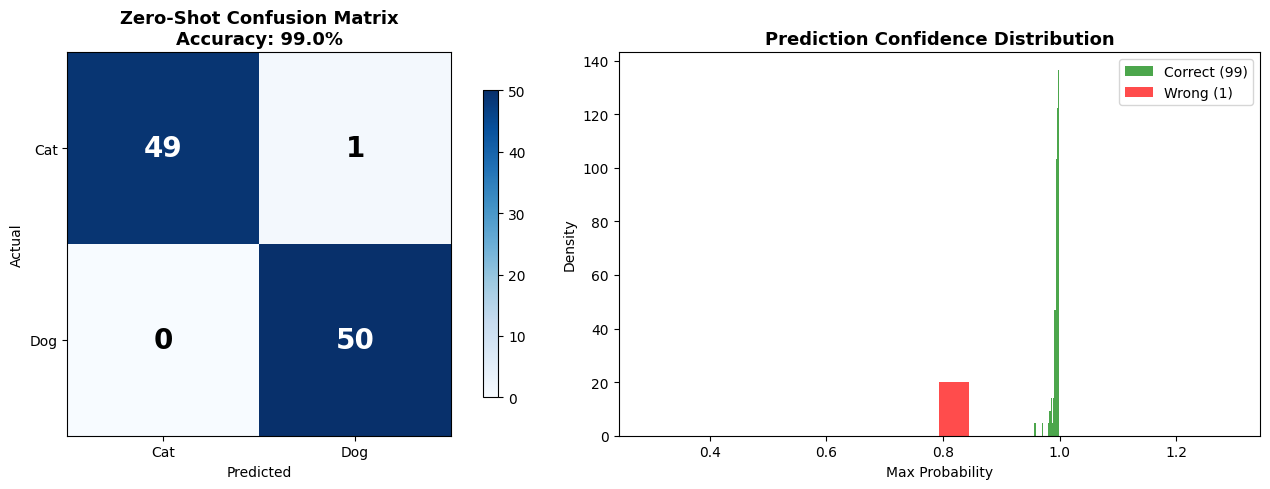

In [15]:
# Measure zero-shot classification accuracy on the entire dataset
print("📊 Running CLIP zero-shot classification on the full dataset...\n")

class_texts = ["a photo of a dog", "a photo of a cat"]
all_preds = []
all_probs = []

batch_size = 16
for i in tqdm(range(0, len(image_paths), batch_size)):
    batch_paths = image_paths[i:i+batch_size]
    batch_images = [Image.open(p).convert('RGB') for p in batch_paths]

    probs, pred_idx = clip_zero_shot_classify(batch_images, class_texts)
    all_probs.extend(probs.tolist())
    all_preds.extend(['dog' if p == 0 else 'cat' for p in pred_idx])

acc = accuracy_score(image_labels, all_preds)
cm = confusion_matrix(image_labels, all_preds, labels=['cat', 'dog'])

print(f"\n{'='*50}")
print(f"  🎯 CLIP Zero-Shot Accuracy: {acc:.1%}")
print(f"  (achieved with 0 training examples!)")
print(f"{'='*50}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
im = axes[0].imshow(cm, cmap='Blues')
axes[0].set_xticks([0, 1]); axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(['Cat', 'Dog']); axes[0].set_yticklabels(['Cat', 'Dog'])
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')
axes[0].set_title(f'Zero-Shot Confusion Matrix\nAccuracy: {acc:.1%}', fontsize=13, fontweight='bold')
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=20, fontweight='bold',
                    color='white' if cm[i, j] > cm.max()/2 else 'black')
plt.colorbar(im, ax=axes[0], shrink=0.8)

# Confidence distribution
correct_confs = [max(p) for p, gt, pred in zip(all_probs, image_labels, all_preds) if gt == pred]
wrong_confs = [max(p) for p, gt, pred in zip(all_probs, image_labels, all_preds) if gt != pred]
axes[1].hist(correct_confs, bins=20, alpha=0.7, color='green', label=f'Correct ({len(correct_confs)})', density=True)
if wrong_confs:
    axes[1].hist(wrong_confs, bins=20, alpha=0.7, color='red', label=f'Wrong ({len(wrong_confs)})', density=True)
axes[1].set_xlabel('Max Probability'); axes[1].set_ylabel('Density')
axes[1].set_title('Prediction Confidence Distribution', fontsize=13, fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 8. Image-Text Similarity Matrix

The core of CLIP: images and texts live in **the same embedding space**.
Let's verify this visually.

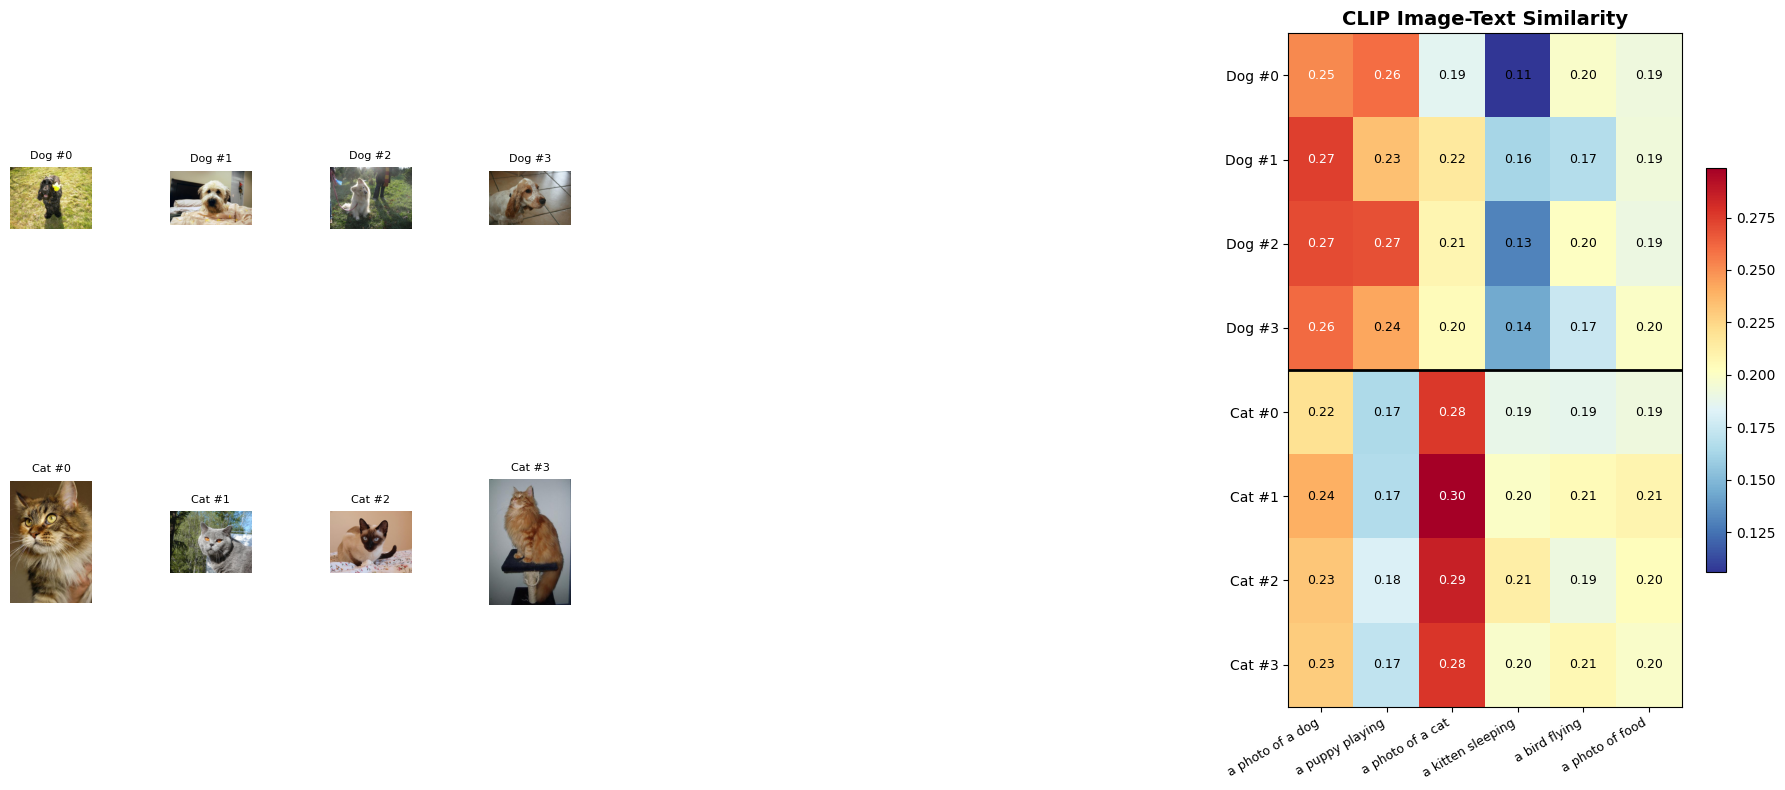

💡 관찰: Dog 이미지는 'dog' 텍스트와, Cat 이미지는 'cat' 텍스트와 높은 유사도를 보입니다.
   관련 없는 텍스트('bird', 'food')와는 유사도가 낮습니다.


In [16]:
@torch.no_grad()
def get_clip_image_embeddings(images):
    """Extract image embeddings with the CLIP image encoder."""
    inputs = clip_processor(images=images, return_tensors="pt").to(device)
    embeds = clip_model.get_image_features(**inputs)
    return F.normalize(embeds, p=2, dim=1).cpu().numpy()

@torch.no_grad()
def get_clip_text_embeddings(texts):
    """Extract text embeddings with the CLIP text encoder."""
    inputs = clip_processor(text=texts, return_tensors="pt", padding=True).to(device)
    embeds = clip_model.get_text_features(**inputs)
    return F.normalize(embeds, p=2, dim=1).cpu().numpy()

# Select sample images (4 dogs, 4 cats)
sample_dog_paths = image_paths[:4]
sample_cat_paths = image_paths[NUM_IMAGES_PER_CLASS:NUM_IMAGES_PER_CLASS+4]
sample_paths = sample_dog_paths + sample_cat_paths
sample_images = [Image.open(p).convert('RGB') for p in sample_paths]

# Text prompts
text_prompts = [
    "a photo of a dog",
    "a puppy playing",
    "a photo of a cat",
    "a kitten sleeping",
    "a bird flying",
    "a photo of food",
]

# Extract embeddings
img_embeds = get_clip_image_embeddings(sample_images)
txt_embeds = get_clip_text_embeddings(text_prompts)

# Image-Text Similarity Matrix
similarity = img_embeds @ txt_embeds.T

fig = plt.figure(figsize=(18, 8))
gs = fig.add_gridspec(2, len(sample_images) + 1, width_ratios=[1]*len(sample_images) + [6])

# Image thumbnails (left)
for i, img in enumerate(sample_images):
    ax = fig.add_subplot(gs[i // 4, i % 4])
    ax.imshow(img)
    label = 'Dog' if i < 4 else 'Cat'
    ax.set_title(f'{label} #{i % 4}', fontsize=8)
    ax.axis('off')

# Similarity heatmap (right)
ax_heatmap = fig.add_subplot(gs[:, -1])
im = ax_heatmap.imshow(similarity, cmap='RdYlBu_r', aspect='auto')

img_labels_show = [f"Dog #{i}" for i in range(4)] + [f"Cat #{i}" for i in range(4)]
ax_heatmap.set_yticks(range(len(img_labels_show)))
ax_heatmap.set_yticklabels(img_labels_show, fontsize=10)
ax_heatmap.set_xticks(range(len(text_prompts)))
ax_heatmap.set_xticklabels(text_prompts, rotation=30, ha='right', fontsize=9)
ax_heatmap.set_title('CLIP Image-Text Similarity', fontsize=14, fontweight='bold')

for i in range(len(sample_images)):
    for j in range(len(text_prompts)):
        ax_heatmap.text(j, i, f'{similarity[i,j]:.2f}', ha='center', va='center', fontsize=9,
                       color='white' if similarity[i,j] > 0.25 else 'black')

ax_heatmap.axhline(y=3.5, color='black', linewidth=2)
plt.colorbar(im, ax=ax_heatmap, shrink=0.6)

plt.tight_layout()
plt.show()

print("💡 Observation: dog images have high similarity to 'dog' text; cat images have high similarity to 'cat' text.")
print("   Similarity to unrelated text ('bird', 'food') is low.")

---
## 9. Text Prompt Engineering

CLIP's performance is greatly affected by the **text prompt format**.
We experiment with which prompts produce the best results.

🧪 프롬프트 템플릿별 Zero-Shot 정확도 비교

  Simple           dog                                       →  99.0%
  A photo of       a photo of a dog                          →  99.0%
  Descriptive      a cute dog, a pet animal                  →  99.0%
  This is          this is a dog                             →  99.0%
  Animal type      a dog, which is a canine                  →  99.0%
  Negative         not a cat, this is a dog                  →  99.0%


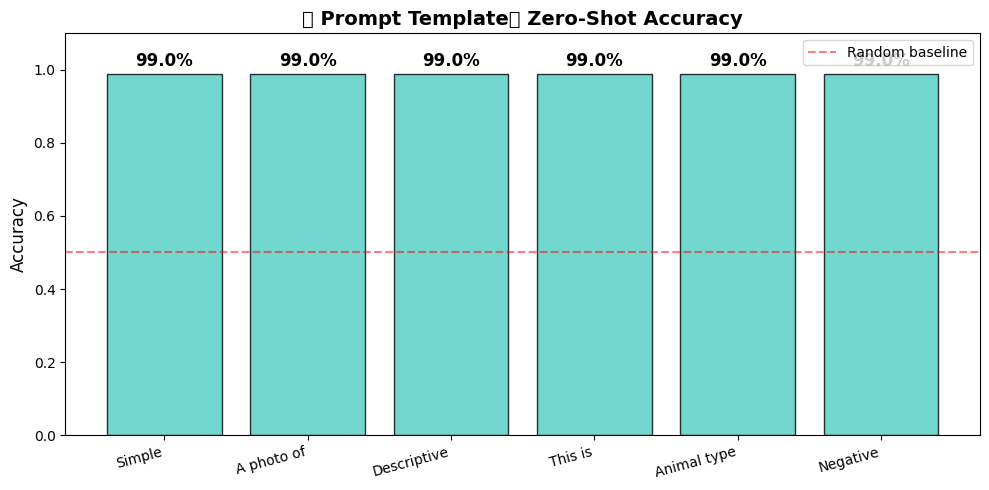


💡 가장 좋은 프롬프트: 'Simple' (99.0%)
   CLIP 논문에서도 'a photo of a {class}' 형태가 가장 효과적이라고 보고했습니다.


In [17]:
# Compare various prompt templates
prompt_templates = {
    'Simple':       ['dog', 'cat'],
    'A photo of':   ['a photo of a dog', 'a photo of a cat'],
    'Descriptive':  ['a cute dog, a pet animal', 'a cute cat, a pet animal'],
    'This is':      ['this is a dog', 'this is a cat'],
    'Animal type':  ['a dog, which is a canine', 'a cat, which is a feline'],
    'Negative':     ['not a cat, this is a dog', 'not a dog, this is a cat'],
}

print("🧪 Zero-shot accuracy comparison across prompt templates\n")

results_by_template = {}

# Process all images at once
all_images = [Image.open(p).convert('RGB') for p in image_paths]

for name, prompts in prompt_templates.items():
    preds = []
    for i in range(0, len(all_images), batch_size):
        batch = all_images[i:i+batch_size]
        probs, pred_idx = clip_zero_shot_classify(batch, prompts)
        preds.extend(['dog' if p == 0 else 'cat' for p in pred_idx])

    acc = accuracy_score(image_labels, preds)
    results_by_template[name] = acc
    print(f"  {name:15s}  {prompts[0]:40s}  →  {acc:.1%}")

# Visualization
fig, ax = plt.subplots(figsize=(10, 5))
names = list(results_by_template.keys())
accs = list(results_by_template.values())
colors = ['#4ECDC4' if a == max(accs) else '#95A5A6' for a in accs]

bars = ax.bar(names, accs, color=colors, edgecolor='black', alpha=0.8)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Accuracy', fontsize=12)
ax.set_title('📝 Zero-Shot Accuracy by Prompt Template', fontsize=14, fontweight='bold')
ax.axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Random baseline')
ax.legend()

for bar, acc in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
           f'{acc:.1%}', ha='center', fontsize=12, fontweight='bold')

plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

best = max(results_by_template, key=results_by_template.get)
print(f"\n💡 Best prompt: '{best}' ({results_by_template[best]:.1%})")
print("   The CLIP paper also reports that the form 'a photo of a {class}' is most effective.")

---
## 10. CLIP Embedding Space (t-SNE)

We visualize CLIP's **multimodal embedding space**.
We confirm that images and texts share the same space.

In [18]:
# Extract image embeddings (full)
print("🔄 Extracting CLIP image embeddings...")
all_img_embeds = []
for i in tqdm(range(0, len(image_paths), batch_size)):
    batch = [Image.open(p).convert('RGB') for p in image_paths[i:i+batch_size]]
    embeds = get_clip_image_embeddings(batch)
    all_img_embeds.append(embeds)
all_img_embeds = np.concatenate(all_img_embeds, axis=0)

# Visualize text embeddings together
mixed_texts = [
    "a photo of a dog", "a puppy", "a golden retriever", "a loyal dog",
    "a photo of a cat", "a kitten", "a tabby cat", "a cute cat",
]
mixed_text_labels = ['dog']*4 + ['cat']*4
text_embeds = get_clip_text_embeddings(mixed_texts)

# Concatenate images + texts and run t-SNE
combined = np.concatenate([all_img_embeds, text_embeds], axis=0)
combined_labels = image_labels + mixed_text_labels
combined_types = ['image'] * len(image_labels) + ['text'] * len(mixed_text_labels)

print("🔄 Computing t-SNE...")
tsne = TSNE(n_components=2, perplexity=min(30, len(combined)-1), random_state=SEED)
tsne_2d = tsne.fit_transform(combined)

print("✅ Done!")

🔄 CLIP 이미지 임베딩 추출 중...


  0%|          | 0/7 [00:00<?, ?it/s]

🔄 t-SNE 계산 중...
✅ 완료!


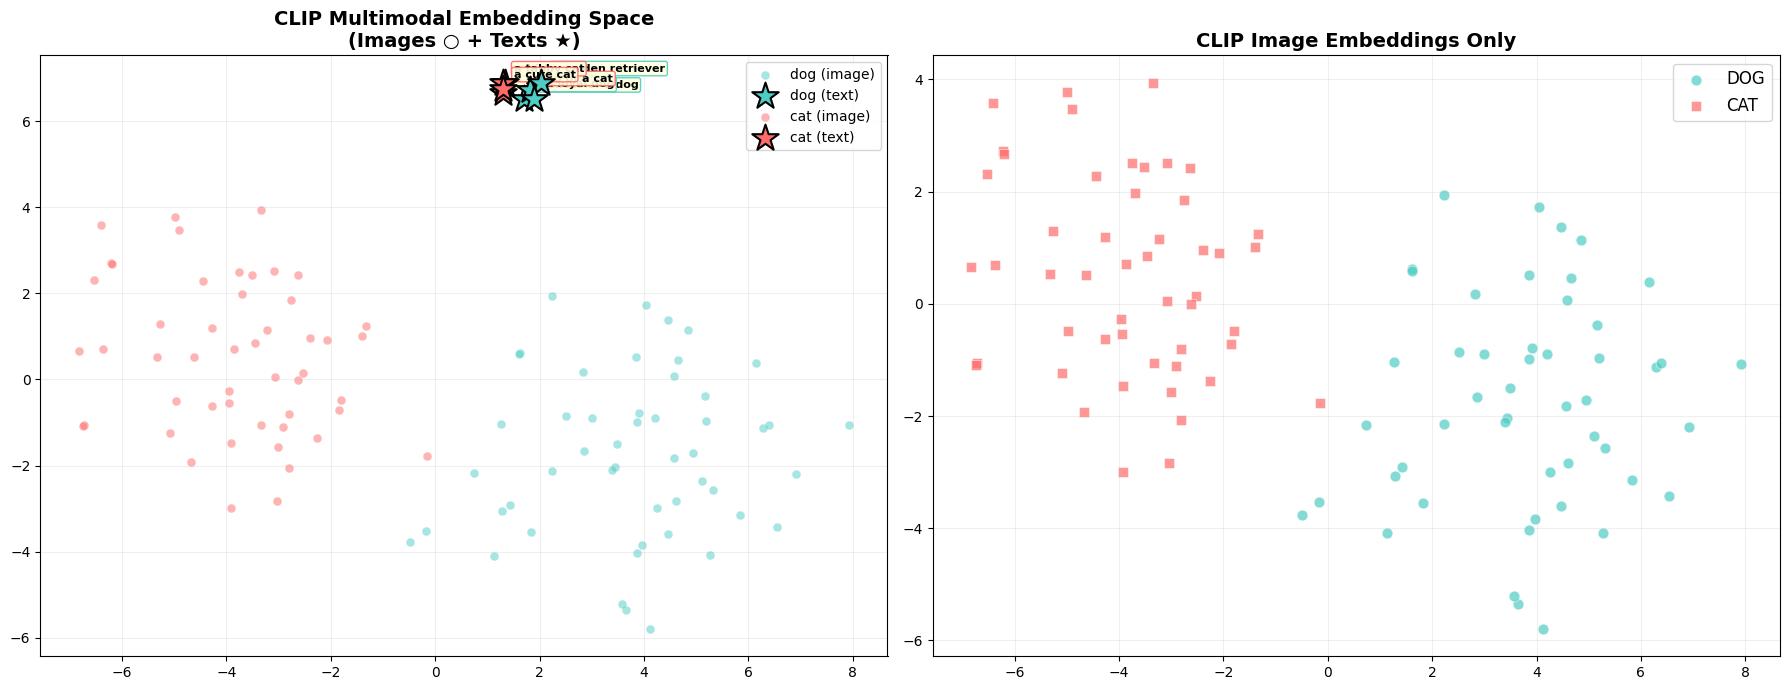

💡 핵심 관찰:
   1. 이미지와 텍스트가 같은 공간에 위치합니다! (CLIP의 핵심)
   2. Dog 텍스트(★)는 Dog 이미지(○) 근처에, Cat 텍스트(★)는 Cat 이미지(○) 근처에 있습니다.
   3. 이것이 zero-shot classification이 작동하는 원리입니다.


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# (1) Combined image + text t-SNE
for cls, color in [('dog', '#4ECDC4'), ('cat', '#FF6B6B')]:
    # Images (small circle)
    mask = (np.array(combined_labels) == cls) & (np.array(combined_types) == 'image')
    axes[0].scatter(tsne_2d[mask, 0], tsne_2d[mask, 1], c=color, marker='o',
                   s=40, alpha=0.5, edgecolors='white', linewidth=0.3,
                   label=f'{cls} (image)')

    # Texts (large star)
    mask = (np.array(combined_labels) == cls) & (np.array(combined_types) == 'text')
    axes[0].scatter(tsne_2d[mask, 0], tsne_2d[mask, 1], c=color, marker='*',
                   s=400, edgecolors='black', linewidth=1.5, zorder=5,
                   label=f'{cls} (text)')

    # Text labels
    text_mask_indices = np.where(mask)[0]
    text_start = len(image_labels)
    for idx in text_mask_indices:
        text_idx = idx - text_start
        if 0 <= text_idx < len(mixed_texts):
            axes[0].annotate(mixed_texts[text_idx], (tsne_2d[idx, 0], tsne_2d[idx, 1]),
                           fontsize=8, fontweight='bold', textcoords='offset points',
                           xytext=(8, 8), bbox=dict(boxstyle='round,pad=0.2',
                           facecolor='lightyellow', edgecolor=color, alpha=0.9))

axes[0].set_title('CLIP Multimodal Embedding Space\n(Images ○ + Texts ★)', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=10, loc='best')
axes[0].grid(alpha=0.2)

# (2) Image-only t-SNE
img_only_2d = tsne_2d[:len(image_labels)]
for cls, color, marker in [('dog', '#4ECDC4', 'o'), ('cat', '#FF6B6B', 's')]:
    mask = np.array(image_labels) == cls
    axes[1].scatter(img_only_2d[mask, 0], img_only_2d[mask, 1], c=color, marker=marker,
                   s=60, alpha=0.7, edgecolors='white', linewidth=0.5, label=cls.upper())

axes[1].set_title('CLIP Image Embeddings Only', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=12)
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("💡 Key observations:")
print("   1. Images and texts live in the same space! (the core of CLIP)")
print("   2. Dog text (★) sits near dog images (○), cat text (★) near cat images (○).")
print("   3. This is the principle that makes zero-shot classification work.")

---
## 11. Comprehensive Comparison of Lab 1~3: DINO vs CLIP

We compare DINO (self-supervised) from Lab 1 with CLIP (contrastive) from Lab 3.

| | DINO ViT | CLIP ViT |
|---|---|---|
| Training | Self-distillation (image only) | Contrastive (image + text) |
| Input | Image | Image + Text |
| Embedding space | Vision only | Multimodal (shared) |
| Classification | Requires linear probing | Zero-shot is possible |

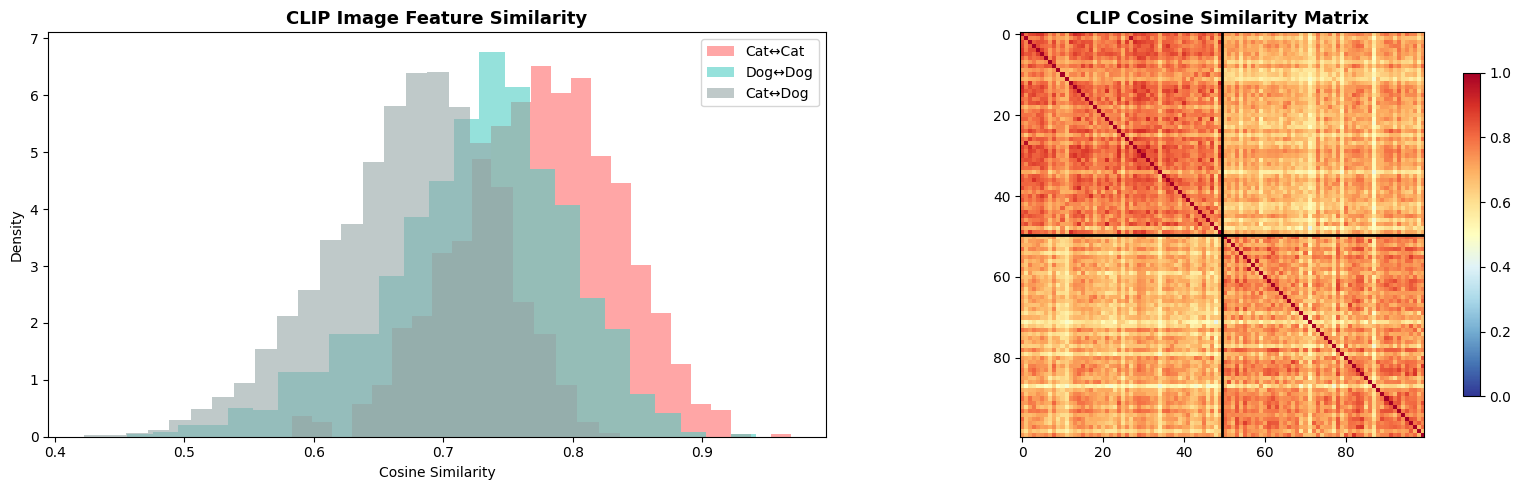


📊 CLIP Cosine Similarity Statistics:
  Cat↔Cat (intra): 0.7735 ± 0.0607
  Dog↔Dog (intra): 0.7246 ± 0.0709
  Cat↔Dog (inter): 0.6738 ± 0.0641

  (Lab 1의 DINO 결과와 비교해보세요!)


In [20]:
# Cosine similarity analysis using CLIP image features (compare to Lab 1)
clip_feat_norm = all_img_embeds  # already normalized
clip_sim = cosine_similarity(clip_feat_norm)

labels_arr = np.array(image_labels)
cat_idx = np.where(labels_arr == 'cat')[0]
dog_idx = np.where(labels_arr == 'dog')[0]

cat_cat = clip_sim[np.ix_(cat_idx, cat_idx)]
dog_dog = clip_sim[np.ix_(dog_idx, dog_idx)]
cat_dog = clip_sim[np.ix_(cat_idx, dog_idx)]

cc = cat_cat[np.triu_indices_from(cat_cat, k=1)]
dd = dog_dog[np.triu_indices_from(dog_dog, k=1)]
cd = cat_dog.flatten()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# CLIP similarity distribution
axes[0].hist(cc, bins=25, alpha=0.6, label='Cat↔Cat', color='#FF6B6B', density=True)
axes[0].hist(dd, bins=25, alpha=0.6, label='Dog↔Dog', color='#4ECDC4', density=True)
axes[0].hist(cd, bins=25, alpha=0.6, label='Cat↔Dog', color='#95A5A6', density=True)
axes[0].set_xlabel('Cosine Similarity')
axes[0].set_ylabel('Density')
axes[0].set_title('CLIP Image Feature Similarity', fontsize=13, fontweight='bold')
axes[0].legend()

# CLIP similarity heatmap
sorted_idx = np.concatenate([cat_idx, dog_idx])
sorted_sim = clip_sim[np.ix_(sorted_idx, sorted_idx)]
im = axes[1].imshow(sorted_sim, cmap='RdYlBu_r', vmin=0, vmax=1)
axes[1].axhline(y=len(cat_idx)-0.5, color='black', linewidth=2)
axes[1].axvline(x=len(cat_idx)-0.5, color='black', linewidth=2)
axes[1].set_title('CLIP Cosine Similarity Matrix', fontsize=13, fontweight='bold')
plt.colorbar(im, ax=axes[1], shrink=0.8)

plt.tight_layout()
plt.show()

print(f"\n📊 CLIP Cosine Similarity Statistics:")
print(f"  Cat↔Cat (intra): {cc.mean():.4f} ± {cc.std():.4f}")
print(f"  Dog↔Dog (intra): {dd.mean():.4f} ± {dd.std():.4f}")
print(f"  Cat↔Dog (inter): {cd.mean():.4f} ± {cd.std():.4f}")
print(f"\n  (Compare with the DINO results from Lab 1!)")

🔍 CLIP Image Retrieval — 텍스트로 이미지 검색



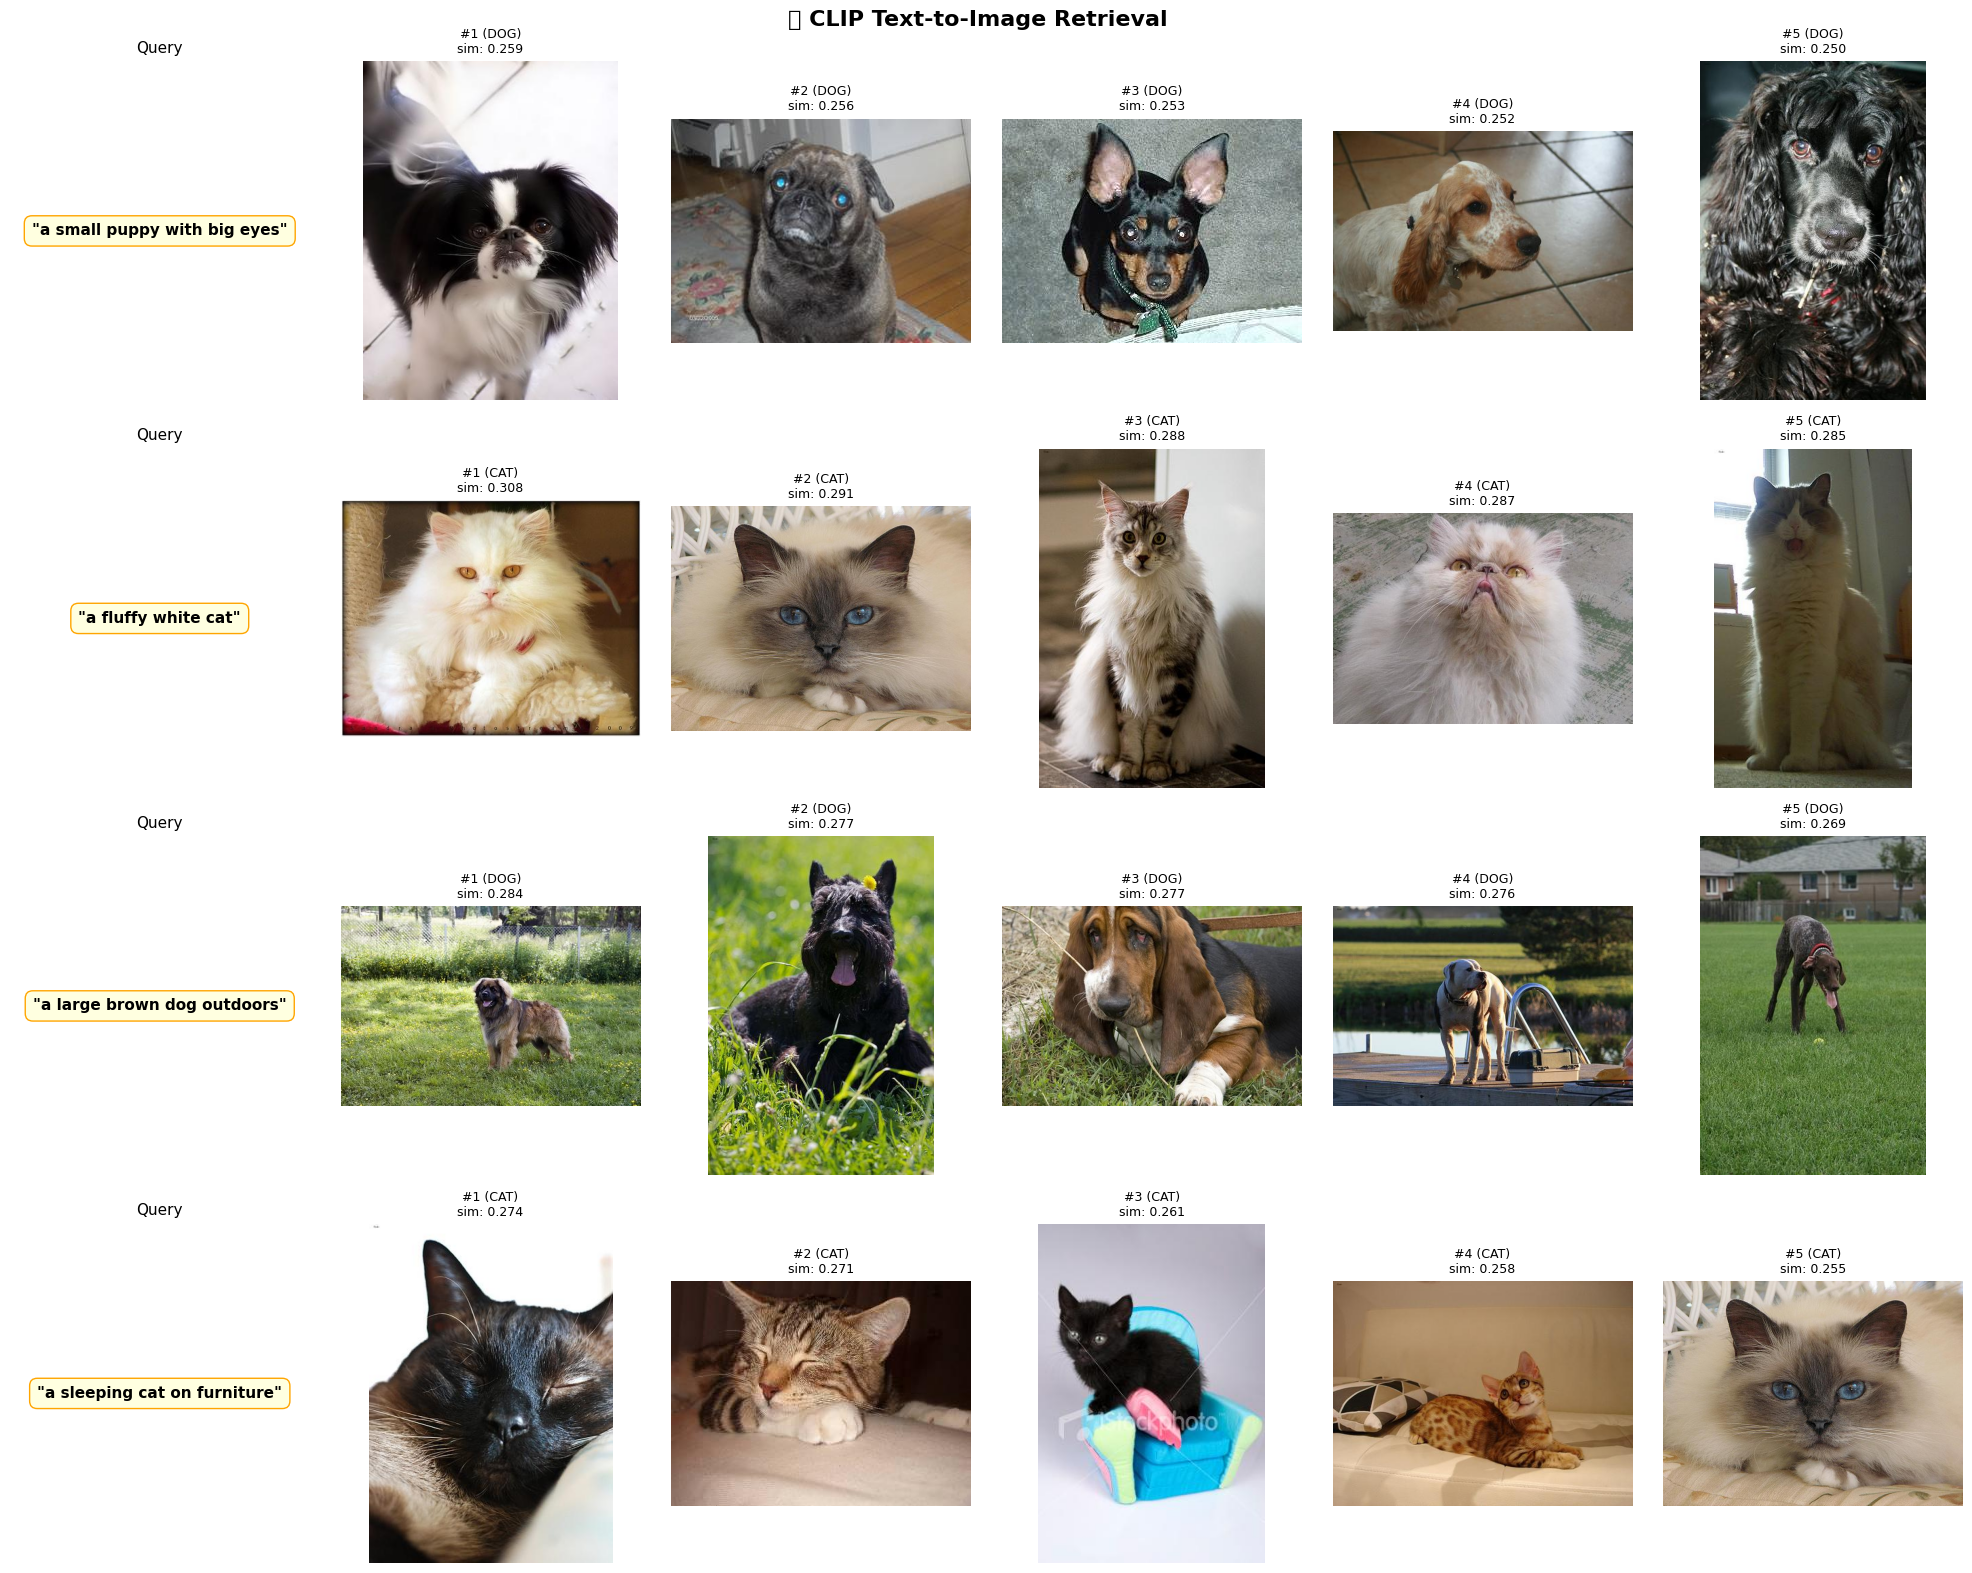

In [21]:
# Demo CLIP's image retrieval — find images using text
print("🔍 CLIP Image Retrieval — searching images with text\n")

search_queries = [
    "a small puppy with big eyes",
    "a fluffy white cat",
    "a large brown dog outdoors",
    "a sleeping cat on furniture",
]

fig, axes = plt.subplots(len(search_queries), 6, figsize=(20, 4 * len(search_queries)))
fig.suptitle('🔍 CLIP Text-to-Image Retrieval', fontsize=16, fontweight='bold')

for row, query in enumerate(search_queries):
    query_embed = get_clip_text_embeddings([query])
    similarities = (query_embed @ all_img_embeds.T).flatten()
    top_indices = similarities.argsort()[::-1][:5]

    # Query text
    axes[row, 0].text(0.5, 0.5, f'"{query}"', ha='center', va='center',
                      fontsize=11, fontweight='bold', wrap=True,
                      transform=axes[row, 0].transAxes,
                      bbox=dict(boxstyle='round,pad=0.5', facecolor='lightyellow', edgecolor='orange'))
    axes[row, 0].set_title('Query', fontsize=11)
    axes[row, 0].axis('off')

    # Top-5 results
    for col, idx in enumerate(top_indices):
        img = Image.open(image_paths[idx]).convert('RGB')
        axes[row, col + 1].imshow(img)
        gt = image_labels[idx].upper()
        axes[row, col + 1].set_title(f'#{col+1} ({gt})\nsim: {similarities[idx]:.3f}', fontsize=9)
        axes[row, col + 1].axis('off')

plt.tight_layout()
plt.show()

---
## 📝 Summary

### Part A: BERT
| Experiment | Result |
|------|------|
| **Tokenization** | WordPiece-style subword tokenization |
| **Sentence Embedding** | High cosine similarity for semantically similar sentences |
| **MLM** | Accurately predicts the contextually appropriate word |

### Part B: CLIP
| Experiment | Result |
|------|------|
| **Zero-Shot Classification** | High Dog/Cat accuracy without training |
| **Image-Text Similarity** | Accurate cross-modal image-text similarity |
| **Prompt Engineering** | The prompt format strongly affects performance |
| **Multimodal Embedding** | Images and texts are aligned in the same space |
| **Image Retrieval** | Search related images with text |

### Connecting Labs 1~3

| Lab | Model | Training | Core ability |
|-----|------|------|----------|
| 1 | DINO ViT | Self-supervised (image) | Feature learning, attention map |
| 2 | Grounding DINO + SAM | Supervised + Foundation | Open-set detection + segmentation |
| 3-A | BERT | Self-supervised (text, MLM) | Text understanding |
| 3-B | CLIP | Contrastive (image + text) | Multimodal alignment, zero-shot |

### The Foundation Model Timeline
```
BERT (2019)  →  Learns to understand text
DINO (2021)  →  Learns to understand images via self-supervision
CLIP (2021)  →  Learns to connect images and text
SAM  (2023)  →  Learns to segment anything
Grounding DINO (2023) → Learns to find anything via text
```

---
*This notebook was created for BERT & CLIP practice.*